As hinted in the l2_notes, in this directory l3_notes we want to predict the char based on three previous chars (block_size = 3). 

# Basic mechanism

The input is three characters, and the output should be one character.

Firstly, we want to convert each of the 27 characters (a -- z and .) to a vector of some size, which we call embedding. The size of the vector is subject to change, but in this notebook we are going to keep it as 2 so that we can visualize the 27 vectors in a 2D graph with matplotlib. 

Secondly, we want to concatenate the three embedding vectors into one vector (in this notebook, with the size 3*2), and then use a layer of neurons to produce an output vector with a size subject to choice (input @ w + b, and then tanh). The size of the output vector determines the power of the neural network. With a larger size, the model is able to fit the desired output in the dataset easily, but it may overfit the dataset and not produce a result with originality. In this notebook we choose the size of the output vector to be 100, which we will change in another notebook. 

Thirdly, we use another parameter matrix to convert the output of size 100 to another logits of size 27. And then we just follow the same procedure as nn_for_bigram in l2_notes: exponentiate to get counts, and normalize to get probablities, and then obtain the loss function. 

Up to this point, we already have a loss function for back propogation, and therefore, we can tune the parameters to minimize the loss function.Hopefully, the result can go below the minimal loss value in l2_notes. 

**Mini batch**

Up to this point, in one round of looking for value of loss function, we iterate through all of the examples in the dataset, which takes much time and makes the process of training unefficient. Therefore, we want to speed up the time used to find the value of the loss function. 

The solution is to get merely a little proportion of the examples in the dataset, which we can sample, and only use that sample to get the loss function. 

Of course, since the sample is different each time, the value of the loss function will have a lot of noise in it (much fluctuation). However, it prevents the risk of overfit and ensures that the learning resulted from one sample should be able to be applied to other samples as well. 

Here we are just going to use the sample size of 32.

![model representation](model.png)

The image is also available in the paper in l3_notes: paper.pdf

# Preparation

In [4]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()
words[:10]

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# Implementation of the Mechanism

In [66]:
# initialize every parameters to be used and require grads for every one of them
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator = g)
W1 = torch.randn((3*2, 100), generator = g)
b1 = torch.randn(100, generator = g)
W2 = torch.randn((100, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
for parameter in parameters:
    parameter.requires_grad = True

In [59]:
# check the number of 1*1 parameters
sum([parameter.nelement() for parameter in parameters])

3481

### getting embedded vector

In [60]:
# assume we have three characters: 'all', and we want to get the three embedded vectors of 'a', 'l'. 'l'
a = stoi['a']
l = stoi['l']
print(C[a], C[l], C[l]) # however, this way is too slow and we want to be faster when working with a large dataset
print(C[[a, l, l]])

# however, we can have a list of three characters, like here [0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5]
# luckily, torch is super flexible and can help solve the problem directly with no modification as long as the input is a tensor, which is the 
example = [[0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5]]
example = torch.tensor(example)
print(C[example])
print([C[individual] for individual in example]) # you can check whether they are the same


tensor([-0.0274, -1.1008], grad_fn=<SelectBackward0>) tensor([-0.0707,  2.4968], grad_fn=<SelectBackward0>) tensor([-0.0707,  2.4968], grad_fn=<SelectBackward0>)
tensor([[-0.0274, -1.1008],
        [-0.0707,  2.4968],
        [-0.0707,  2.4968]], grad_fn=<IndexBackward0>)
tensor([[[ 1.5674, -0.2373],
         [-0.0274, -1.1008],
         [ 0.2859, -0.0296]],

        [[-0.0274, -1.1008],
         [ 0.2859, -0.0296],
         [-1.5471,  0.6049]],

        [[ 0.2859, -0.0296],
         [-1.5471,  0.6049],
         [ 0.0791,  0.9046]],

        [[-1.5471,  0.6049],
         [ 0.0791,  0.9046],
         [-0.4713,  0.7868]]], grad_fn=<IndexBackward0>)
[tensor([[ 1.5674, -0.2373],
        [-0.0274, -1.1008],
        [ 0.2859, -0.0296]], grad_fn=<IndexBackward0>), tensor([[-0.0274, -1.1008],
        [ 0.2859, -0.0296],
        [-1.5471,  0.6049]], grad_fn=<IndexBackward0>), tensor([[ 0.2859, -0.0296],
        [-1.5471,  0.6049],
        [ 0.0791,  0.9046]], grad_fn=<IndexBackward0>), tensor([

### concatenating three embedded vector

In [61]:
# literally concatenating
print(torch.cat((C[a], C[l], C[l]))) # however, again, that is too complicated for larger examples, so we need another way

# there is another function in torch called "unbind"
embedded = C[example]
print(torch.unbind(embedded, 1)) # the '1' controls which dimension it unbinds
print(torch.cat(torch.unbind(embedded, 1), 1)) # the second '1' controls which dimension it concatenate
# luckily, torch is flexible enough to that too :)

# however, the dimension is kind of complicated and annoying to think about
# and luckily, there is another faster way to 'concatenate'
# this functino is 'view' which can change the size of the tensor
print(embedded.view(len(example), 6)) # obviously len(example) is 4 here
print(embedded.view(-1, 6)) 
# since len(example) * 6 should be the total number of 1*1 tensor, -1 tells torch to figure out the size of the first dimension automatically
# now this is concise enough for us to work forward

tensor([-0.0274, -1.1008, -0.0707,  2.4968, -0.0707,  2.4968],
       grad_fn=<CatBackward0>)
(tensor([[ 1.5674, -0.2373],
        [-0.0274, -1.1008],
        [ 0.2859, -0.0296],
        [-1.5471,  0.6049]], grad_fn=<UnbindBackward0>), tensor([[-0.0274, -1.1008],
        [ 0.2859, -0.0296],
        [-1.5471,  0.6049],
        [ 0.0791,  0.9046]], grad_fn=<UnbindBackward0>), tensor([[ 0.2859, -0.0296],
        [-1.5471,  0.6049],
        [ 0.0791,  0.9046],
        [-0.4713,  0.7868]], grad_fn=<UnbindBackward0>))
tensor([[ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296],
        [-0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049],
        [ 0.2859, -0.0296, -1.5471,  0.6049,  0.0791,  0.9046],
        [-1.5471,  0.6049,  0.0791,  0.9046, -0.4713,  0.7868]],
       grad_fn=<CatBackward0>)
tensor([[ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296],
        [-0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049],
        [ 0.2859, -0.0296, -1.5471,  0.6049,  0.0791,  0.9046],
  

### forward pass, backward propogation, update

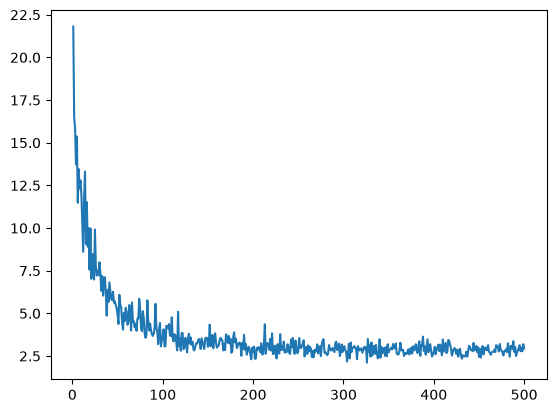

In [62]:
# record loss function with respect to time of iteration
stepi = []
lossi = []
for i in range(500):

    # construction of mini batch of size 32
    ix = torch.randint(0, X.shape[0], (32,), generator = g) # get random integer in ]0, X.shape[0])

    # forward pass
    embedded = C[X[ix]] # find the embedded
    concat = embedded.view(-1, 6) # concatenate
    h = torch.tanh(concat @ W1 + b1) # the output of the hidden layer (h -> 'hidden')
    # now it is the same process as in l2_notes
    logits = h @ W2 + b2
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims = True)
    loss = -probs[torch.arange(32), Y[ix]].log().mean()

    # record the current loss function value
    stepi.append(i+1)
    lossi.append(loss.item()) # since loss is an torch tensor object

    # back propogation
    for parameter in parameters:
        parameter.grad = None # here we cannot put 0 since it needs to match the shape of parameter
    loss.backward()

    # update
    for parameter in parameters:
        parameter.data -= 0.1 * parameter.grad

plt.plot(stepi, lossi)


### forward pass, back propogation, update (consise)

There are a few steps that can be put into one step that is already defined in the pytorch library. Therefore, we are going to use those already built functions since they can reduce the lines of code, occupy less memory and reduce the calculation needed for back propogation. 
```
embedded = C[X[ix]] 
concat = embedded.view(-1, 6) 
h = torch.tanh(concat @ W1 + b1) 
```
The code above can be written as 
```
h = torch.tanh(C[X[ix]].view(-1, 6) @ W1 + b1)
```

At the same time, we can simplify another chunk of code.
```
logits = h @ W2 + b2
counts = logits.exp()
probs = counts / counts.sum(1, keepdims = True)
loss = -probs[torch.arange(32), Y[ix]].log().mean()
```
The code above can be written as, using *cross_entropy*, 
```
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y[ix])
```
or even 
```
loss = F.cross_entropy(h @ W2 + b2, Y[ix])
```
Here we are going to use the shorter code, which is the second one.

We are going to make another modification here: when looking at the graph of the loss function over time, the decrement is very dramatic, and we want to make the drop less high. Therefore, we can use loss.log10() to squash the range of the function to be thiner. 

However, there is another problem: the value of the loss function we get at last is only obtained with a minibatch of 32 samples, which have too much uncertainty. Therefore, we have to use the whole dataset to obtain the value of the loss function. It is true that we may encounter the situation of overfitting and obtain an unrepresentative loss function value, which is the problem that we intend to solve in the other notebook in l3_notes. 

tensor(2.6273, grad_fn=<NllLossBackward0>)


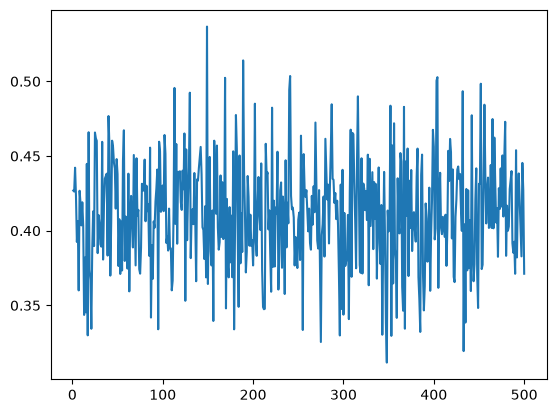

In [72]:
stepi = []
lossi_log = []
for i in range(500):
    # construction of mini batch of size 32
    ix = torch.randint(0, X.shape[0], (32,), generator = g)

    # forward pass
    h = torch.tanh(C[X[ix]].view(-1, 6) @ W1 + b1)
    loss = F.cross_entropy(h @ W2 + b2, Y[ix])

    # record the current loss function value
    stepi.append(i+1)
    lossi_log.append(loss.log10().item())

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    for parameter in parameters:
        parameter.data -= 0.1 * parameter.grad

plt.plot(stepi, lossi_log)
loss = F.cross_entropy(torch.tanh(C[X].view(-1, 6) @ W1 + b1) @ W2 + b2, Y)
print(loss)

# Tuning Learning Rate

In the implementation above, we arbitrarily set the learning rate (parameter.data -= 0.1 * parameter.grad) to 0.1. However, we do not know what is the best option for the learning rate, so we intend to find that out in this part. 

By simply changing the learning rate manually, we can discover that the best learning rate should lie between 0.001 and 1. With a learning rate less than 0.001, the model is learning too slow; with a learning rate higher than 1, the model is changing its parameters so fast that it always goes past the point that minimize the loss function. 

However, instead of stepping from 0.001 to 1 arithmetically (1, 3, 5, 7, 9), we step exponentially (0.001, 0.01, 0.1, 1). Due to the limit of the time, we only 300 different learnign rate. 

Since the kernel crashes when conducting the iteration, I have to decrease the number of iteration. 
* we will try only 200 learning rate

In [10]:
# getting the list of learning rate we are going to test
lri = (10 ** torch.linspace(-3, 0, 200)).tolist() # lr as learning rate
# tolist turns a torch tensor into a python list

0.1335451453924179

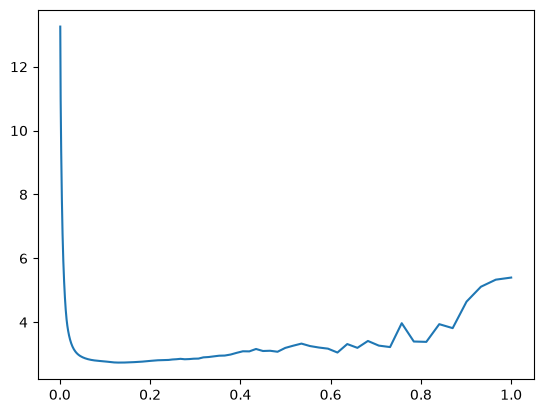

In [11]:
lossi_log = []
for lr in lri:

    # initializa the parameters each time starting to prevent the update of each learning rate interfere with each other
    g = torch.Generator().manual_seed(2147483647)
    C = torch.randn((27, 2), generator = g)
    W1 = torch.randn((3*2, 100), generator = g)
    b1 = torch.randn(100, generator = g)
    W2 = torch.randn((100, 27), generator = g)
    b2 = torch.randn(27, generator = g)
    parameters = [C, W1, b1, W2, b2]
    for parameter in parameters:
        parameter.requires_grad = True


    # iterating 500 times with each learning rate
    for i in range(500):

        # construction of mini batch of size 32
        ix = torch.randint(0, X.shape[0], (32,), generator = g)

        # forward pass
        h = torch.tanh(C[X[ix]].view(-1, 6) @ W1 + b1)
        loss = F.cross_entropy(h @ W2 + b2, Y[ix])

        # back propogation
        for parameter in parameters:
            parameter.grad = None
        loss.backward()

        # update
        for parameter in parameters:
            parameter.data -= lr * parameter.grad

    # record the final loss function value (obtained from the whoel dataset)
    lossi_log.append(F.cross_entropy(torch.tanh(C[X].view(-1, 6) @ W1 + b1) @ W2 + b2, Y).item())

plt.plot(lri, lossi_log)
# get the learning rate with the lowest loss function value
lri[lossi_log.index(min(lossi_log))]
    

Therefore, from now on we change learning rate to 0.133. 

# More

In my opinion, the size of a minibatch can also interfere with the final loss function value as well. However, the effect of minibatch size is deeply intertwined with learning rate. In other words, if we are to try 10 minibatch sizes and 200 learning rate, there are going to be 2,000 iterations to go over, which is surely beyond the capacity of my computer. Although it is possible to manually kick out a lot of possibilities here, it is still hard for my computer, so I will not tune the size of the minibatch for now. 

Hopefully sometime in the future, i can run a notebook on kaggle so that some more powerful computer can run the code instead of my own, and then I will put the code or the link below. However, for now, I will just leave the thought here and sometime maybe i can come back to fill this part. 

--- written on 11/05/2026, the 86th day. 